In this notebook, we first seek to colve some of the more basic problems that exist before, like the crazy noise in the lossi plot, and we want to further torchify and training loop to simplify the process even more. And then, we try ot make the model a Recurence neural Network, and tune the number of hyperparameters to raise the performance for a bit. 

## Loss Log

| Experiment | Training Loss | Validation Loss |
|:---|---:|---:|
| Preparation (Baseline) | 2.1093 | 2.1408 |
| Simplified Training Loop | 2.1080 | 2.1360 |
| Increased Block Size | 1.9997 | 2.0617 |
| RNN | 1.9067 | 2.0180 |
| **RNN Amplified** | **1.7682** | **1.9914** |

## Preparation

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('../names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

for x, y in zip(Xtr[:20], Ytr[:20]):
    print(''.join(itos[ix.item()] for ix in x), '--->', itos[y.item()])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])
... ---> y
..y ---> u
.yu ---> h
yuh ---> e
uhe ---> n
hen ---> g
eng ---> .
... ---> d
..d ---> i
.di ---> o
dio ---> n
ion ---> d
ond ---> r
ndr ---> e
dre ---> .
... ---> x
..x ---> a
.xa ---> v
xav ---> i
avi ---> e


In [2]:
# import classes from the other py file
from torchification_v2 import Linear
from torchification_v2 import Batchnorm1d
from torchification_v2 import Tanh
torch.manual_seed(42) # the generator inside py document is discarded

# Baseline Model

In [9]:
#------------------ parameter initialization -----------------
#-------------------------------------------------------------
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP

C = torch.randn((vocab_size, n_embd))
layers = [
    Linear(n_embd * block_size, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size, bias = False),
]

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    # for layer in layers[:-2]:
    #     if isinstance(layer, Linear):
    #         layer.weight *= 5/3
    # we remove the four lines above since wehave the batchnorm layer

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(f"Number of parameters initialized is {sum(p.nelement() for p in parameters)}") # number of parameters in total
for p in parameters:
    p.requires_grad = True
#-------------------------------------------------------------

#------------------ model training loop -----------------
#--------------------------------------------------------
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
#--------------------------------------------------------

Number of parameters initialized is 6170
      0/ 200000: 3.2953
  10000/ 200000: 1.8710
  20000/ 200000: 2.1466
  30000/ 200000: 2.4560
  40000/ 200000: 1.9981
  50000/ 200000: 2.1412
  60000/ 200000: 2.5017
  70000/ 200000: 2.4619
  80000/ 200000: 2.3363
  90000/ 200000: 1.8510
 100000/ 200000: 2.2767
 110000/ 200000: 2.4899
 120000/ 200000: 2.2371
 130000/ 200000: 2.0415
 140000/ 200000: 1.9256
 150000/ 200000: 2.5171
 160000/ 200000: 2.0760
 170000/ 200000: 2.5784
 180000/ 200000: 1.7706
 190000/ 200000: 2.0239
 200000/ 200000: 2.0041


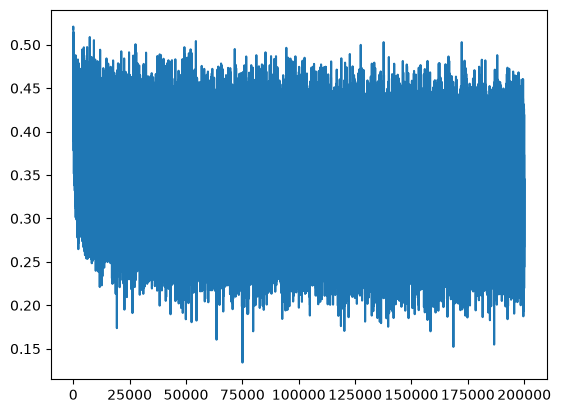

In [12]:
plt.plot(lossi)

In [10]:
#------------ model evaluation and deployment -------------
#----------------------------------------------------------
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x]
    embcat = emb.view(x.shape[0], -1)
    out = embcat
    for layer in layers:
        out = layer(out)
    logits = out
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
split_loss('train')
split_loss('val')
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        embcat = emb.view(1, -1)
        x = embcat
        for layer in layers:
            x = layer(x)
        logits = x
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))
#----------------------------------------------------------

----------------------
train 2.1092519760131836
val 2.1407837867736816
----------------------

tytulyanna.
naton.
casiy.
tao.
die.
dleya.
rub.
crch.
bson.
ford.
ana.
jareet.
dephylonefin.
prexley.
via.
aiyan.
adah.
joura.
bleno.
rhon.


## Smooth the lossi plot

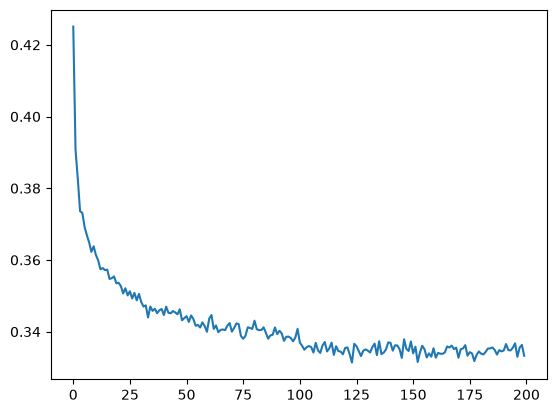

In [16]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

# Adding classes Embedding, FlattenConsecutive, and Sequential to torchification_v2.py

After adding the three classes, we can simplify the code in parameter initialization, model training loop, and model evaluation and deployment. 

* In the embedding class, we wish to be able to randomly initialize the embedding vector in the given dimension, and then there should be a defined function that does the job of ```emb = C[x]``` when being called. Of course, there is parameters related to this kind of layers. 

* In the FlattenConsecutive class, it should do the job of ```embcat = emb.view(x.shape[0], -1)```. However that is the line in the previous notes. Here we want to have a recurrence neural network, RNN, where the ```block_size * n_embd``` variables are not squashed into linear layer together. Instead, they are squashed in pair of 2 step by step (altogether 3 rounds of squashing, (10,10,10,10,10,10,10,10) -> (20,20,20,20); (n,n,n,n) -> (2n, 2n); (n, n) -> (2n)). In this function, we also want to enable us to not only squash in pair of 2, but in pair of other numbers. It is assumed that the user calculates well and makes sure that the process if divisible. (Here we assume that the input tensor has n_dim of 3)

* In the Sequential class, it is intended to a class as a container of different layers stacked together, and when the sequentical is called, the for loop will automatically done. And of course, the parameters of Sequential class include all of the parameters from alll of its layers. 

* There is also something that needs to be changed in the class of Batchnorm1d. Because of the appearance of FlattenConsecutive class, the input into Batchnorm1d layer may have a ndim of 3, in that case, we do not take the mean of only dim 0; instead of we take the mean of dim 0 and 1 together so that the distribution is more uniform. The change can be seen in line 33-36.

In [3]:
# import the newly created classes
from torchification_v2 import Embedding
from torchification_v2 import FlattenConsecutive
from torchification_v2 import Sequential

Number of parameters initialized is 6197
      0/ 200000: 3.3097
  10000/ 200000: 2.4327
  20000/ 200000: 2.2568
  30000/ 200000: 1.9008
  40000/ 200000: 2.2745
  50000/ 200000: 2.1373
  60000/ 200000: 2.4508
  70000/ 200000: 2.2819
  80000/ 200000: 1.9949
  90000/ 200000: 1.8546
 100000/ 200000: 2.2392
 110000/ 200000: 2.0656
 120000/ 200000: 2.3136
 130000/ 200000: 2.1251
 140000/ 200000: 2.3208
 150000/ 200000: 1.7926
 160000/ 200000: 2.5083
 170000/ 200000: 2.2077
 180000/ 200000: 1.9859
 190000/ 200000: 2.6728
 200000/ 200000: 2.2346


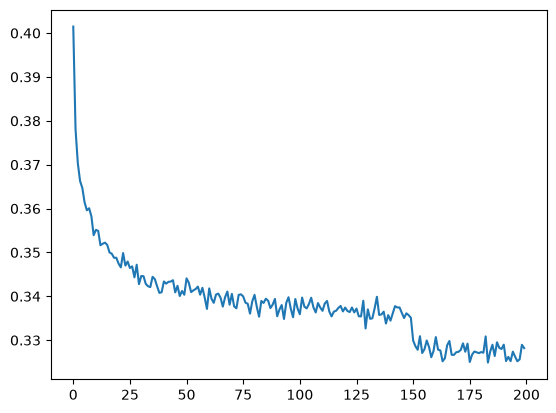

In [ ]:
#------------------ parameter initialization -----------------
#-------------------------------------------------------------
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(block_size), 
    # here we squash all inputs in one layer since it is not a RNN yet
    Linear(block_size*n_embd, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    model.layers[-1].weight *= 0.1

parameters = model.parameters()
print(f"Number of parameters initialized is {sum(p.nelement() for p in parameters)}") # number of parameters in total
for p in parameters:
    p.requires_grad = True
#-------------------------------------------------------------

#------------------ model training loop -----------------
#--------------------------------------------------------
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
#--------------------------------------------------------

#------------------lossi plot visualization-------------------
#-------------------------------------------------------------
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
#-------------------------------------------------------------

In [ ]:
#------------ model evaluation and deployment -------------
#----------------------------------------------------------
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in model.layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
split_loss('train')
split_loss('val')
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))
#----------------------------------------------------------

----------------------
train 2.108002185821533
val 2.1359591484069824
----------------------

breyya.
zaianna.
mareakylpergelzera.
teandoxtleo.
ben.
shaina.
sace.
jani.
asari.
teah.
keskin.
savarkiyah.
dorc.
nat.
evy.
skinna.
ruw.
jerylanir.
jelatalen.
katayton.


# Increase block size to 8

### Preparation

In [7]:
# turning the dataset into the structure of [input] [desired output]
block_size = 8
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

for x, y in zip(Xtr[:20], Ytr[:20]):
    print(''.join(itos[ix.item()] for ix in x), '--->', itos[y.item()])

torch.Size([182580, 8]) torch.Size([182580])
torch.Size([22767, 8]) torch.Size([22767])
torch.Size([22799, 8]) torch.Size([22799])
........ ---> e
.......e ---> b
......eb ---> r
.....ebr ---> i
....ebri ---> m
...ebrim ---> a
..ebrima ---> .
........ ---> h
.......h ---> i
......hi ---> l
.....hil ---> t
....hilt ---> o
...hilto ---> n
..hilton ---> .
........ ---> j
.......j ---> h
......jh ---> e
.....jhe ---> n
....jhen ---> e
...jhene ---> .


Number of parameters initialized is 11197
      0/ 200000: 3.2860
  10000/ 200000: 2.0950
  20000/ 200000: 2.3499
  30000/ 200000: 1.9866
  40000/ 200000: 1.8431
  50000/ 200000: 2.4575
  60000/ 200000: 1.9176
  70000/ 200000: 2.3356
  80000/ 200000: 2.2077
  90000/ 200000: 2.3995
 100000/ 200000: 2.5235
 110000/ 200000: 2.4871
 120000/ 200000: 1.9332
 130000/ 200000: 2.2293
 140000/ 200000: 2.4620
 150000/ 200000: 2.1120
 160000/ 200000: 1.6877
 170000/ 200000: 2.2866
 180000/ 200000: 2.4373
 190000/ 200000: 1.9935
 200000/ 200000: 2.0708


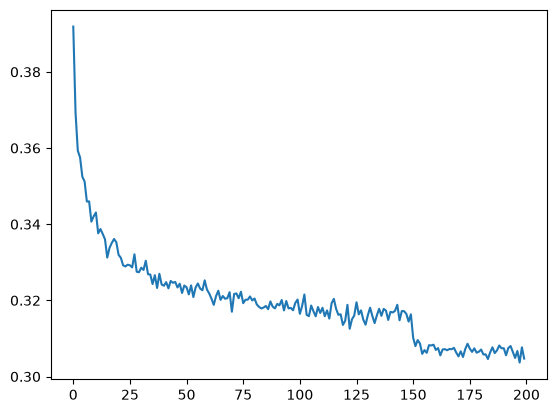

In [ ]:
#------------------ parameter initialization -----------------
#-------------------------------------------------------------
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(block_size), 
    # here we squash all inputs in one layer since it is not a RNN yet
    Linear(block_size*n_embd, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    model.layers[-1].weight *= 0.1

parameters = model.parameters()
print(f"Number of parameters initialized is {sum(p.nelement() for p in parameters)}") # number of parameters in total
for p in parameters:
    p.requires_grad = True
#-------------------------------------------------------------

#------------------ model training loop -----------------
#--------------------------------------------------------
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
#--------------------------------------------------------

#------------------lossi plot visualization-------------------
#-------------------------------------------------------------
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
#-------------------------------------------------------------

In [ ]:
#------------ model evaluation and deployment -------------
#----------------------------------------------------------
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in model.layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
split_loss('train')
split_loss('val')
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))
#----------------------------------------------------------

----------------------
train 1.9996788501739502
val 2.0616846084594727
----------------------

bressyn.
colex.
axe.
kaleeh.
machite.
hacel.
kairy.
aubree.
aoki.
jakell.
trasx.
laah.
sashya.
rhainy.
canensa.
karman.
aleion.
demb.
clenoan.
yoluwaf.


# RNN

The greatest distinction of RNN compared to the models we deisgned before is that RNN squashes the information about 8 previous letters gradually (8 -> 4 -> 2 -> 1), so basically what we are doing here is just to adjust of compilation of layers in model. 

Number of parameters initialized is 22397
      0/ 200000: 3.2818
  10000/ 200000: 2.1409
  20000/ 200000: 2.3016
  30000/ 200000: 2.4183
  40000/ 200000: 2.2275
  50000/ 200000: 2.0494
  60000/ 200000: 1.8176
  70000/ 200000: 2.4189
  80000/ 200000: 2.2072
  90000/ 200000: 1.9701
 100000/ 200000: 1.7595
 110000/ 200000: 1.7868
 120000/ 200000: 1.8348
 130000/ 200000: 1.7298
 140000/ 200000: 1.6776
 150000/ 200000: 2.5031
 160000/ 200000: 1.7554
 170000/ 200000: 1.6860
 180000/ 200000: 2.0473
 190000/ 200000: 1.9963
 200000/ 200000: 2.3954


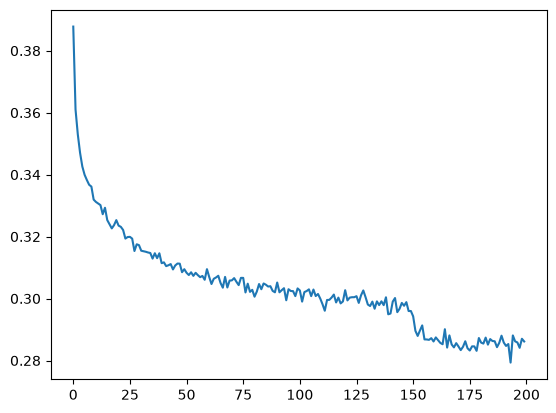

In [10]:
#------------------ parameter initialization -----------------
#-------------------------------------------------------------
n_embd = 10 
n_hidden= 68 

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(2), Linear(2*n_embd,     n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    FlattenConsecutive(2), Linear(2*n_hidden,   n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    FlattenConsecutive(2), Linear(2*n_hidden,   n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    model.layers[-1].weight *= 0.1

parameters = model.parameters()
print(f"Number of parameters initialized is {sum(p.nelement() for p in parameters)}") # number of parameters in total
for p in parameters:
    p.requires_grad = True
#-------------------------------------------------------------

#------------------ model training loop -----------------
#--------------------------------------------------------
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
#--------------------------------------------------------

#------------------lossi plot visualization-------------------
#-------------------------------------------------------------
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
#-------------------------------------------------------------

In [ ]:
#------------ model evaluation and deployment -------------
#----------------------------------------------------------
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in model.layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
split_loss('train')
split_loss('val')
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))
#----------------------------------------------------------

----------------------
train 1.9067485332489014
val 2.0179595947265625
----------------------

joy.
calonm.
karleah.
terra.
diezeli.
devi.
emilynn.
amailian.
jessiyah.
zayhyn.
rafky.
naviash.
sterson.
ington.
lynnes.
lavianni.
anella.
arionny.
chael.
karra.


# RNN Amplified

Number of parameters initialized is 76579
      0/ 200000: 3.2882
  10000/ 200000: 2.2824
  20000/ 200000: 1.7889
  30000/ 200000: 2.2290
  40000/ 200000: 1.4554
  50000/ 200000: 1.8792
  60000/ 200000: 1.6482
  70000/ 200000: 1.9045
  80000/ 200000: 1.9714
  90000/ 200000: 1.9960
 100000/ 200000: 1.6730
 110000/ 200000: 2.2124
 120000/ 200000: 1.7861
 130000/ 200000: 1.9425
 140000/ 200000: 1.8349
 150000/ 200000: 1.7060
 160000/ 200000: 1.6223
 170000/ 200000: 1.4841
 180000/ 200000: 2.0969
 190000/ 200000: 1.7634
 200000/ 200000: 2.1454


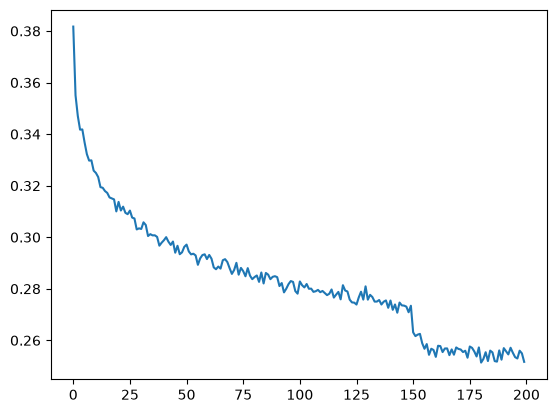

In [12]:
#------------------ parameter initialization -----------------
#-------------------------------------------------------------
n_embd = 24 # 10->24
n_hidden= 128 # 68->128

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(2), Linear(2*n_embd,     n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    FlattenConsecutive(2), Linear(2*n_hidden,   n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    FlattenConsecutive(2), Linear(2*n_hidden,   n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(), 
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    model.layers[-1].weight *= 0.1

parameters = model.parameters()
print(f"Number of parameters initialized is {sum(p.nelement() for p in parameters)}") # number of parameters in total
for p in parameters:
    p.requires_grad = True
#-------------------------------------------------------------

#------------------ model training loop -----------------
#--------------------------------------------------------
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
#--------------------------------------------------------

#------------------lossi plot visualization-------------------
#-------------------------------------------------------------
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
#-------------------------------------------------------------

In [13]:
#------------ model evaluation and deployment -------------
#----------------------------------------------------------
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in model.layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
split_loss('train')
split_loss('val')
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))
#----------------------------------------------------------

----------------------
train 1.7681902647018433
val 1.991446852684021
----------------------

jahmeir.
davaun.
antonio.
ziorman.
syleah.
isak.
vlindo.
jameyah.
gilson.
kaislee.
bobbue.
adaliyah.
monay.
keylynn.
javell.
clocelanr.
abdulronz.
thad.
youan.
ramadel.
